# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [8]:

# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [9]:

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')


In [10]:
plans.head(5) 

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [11]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [12]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [13]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [14]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [15]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [16]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [17]:

    # cantidad de nulos para users
    print(users.isna().sum())
    print(users.isna().mean())


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [18]:

print(usage.isna().sum())
print(usage.isna().mean())


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [19]:
users.describe()
users['city'] = users['city'].fillna('Desconocida')
print(users['city'].isna().sum())   # debe dar 0

0


In [20]:
usage.describe()
usage = usage.dropna(subset=['date'])
print(usage['date'].isna().sum())   # debe dar 0

0


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [21]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

# 1. detectar
for col in columnas_user:
    print(col, users[col].nunique(), users[col].str.strip().str.lower().nunique())

# 2. corregir (solo si el segundo número fue menor)
for col in columnas_user:
    users[col] = users[col].str.strip().str.title()

# 3. verificar
print(users['city'].value_counts(dropna=False))

city 8 8
plan 2 2
Bogotá         808
Cdmx           730
Medellín       616
Desconocida    469
Gdl            450
Cali           424
Mty            407
?               96
Name: city, dtype: int64


- La columna `city` ...
- La columna `plan` ...

In [22]:


# explorar columna categórica de usage

# 1. Conteo de cada valor (incluyendo nulos)
print(usage['type'].value_counts(dropna=False))
print()

# 2. Proporción en porcentaje
print((usage['type'].value_counts(normalize=True, dropna=False) * 100).round(2))
print()

# 3. Detectar variantes de escritura
# (valores distintos tal cual vs. después de limpiar espacios y mayúsculas)
print(usage['type'].nunique(), usage['type'].str.strip().str.lower().nunique())
print()

# 4. Ver los valores únicos exactamente como aparecen
print(usage['type'].unique())



text    22068
call    17882
Name: type, dtype: int64

text    55.24
call    44.76
Name: type, dtype: float64

2 2

['call' 'text']


- La columna `type` ...


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [23]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [24]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [25]:

# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())



2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

In [26]:
# Revisar los años presentes en `date` de usage

print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())
print(users[users['reg_date'].dt.year > 2024])


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64
      user_id first_name last_name  age         city   reg_date     plan  \
40      10040        Ana    Garcia   59     Medellín 2026-05-10   Basico   
56      10056       Luis    Garcia   29         Cdmx 2026-05-10   Basico   
60      10060     Carlos    Torres   45         Cdmx 2026-05-10   Basico   
70      10070    Mariana     Gomez   50         Cdmx 2026-05-10  Premium   
248     10248      Sofia    Garcia   20     Medellín 2026-05-10  Premium   
320     10320      Sofia    Garcia   74          Gdl 2026-05-10  Premium   
326     10326    Mariana    Torres   51     Medellín 2026-05-10  Premium   
505     10505       Luis    Garcia   75         Cdmx 2026-05-10   Basico   
527     10527     Carlos    Torres   71          Mty 2026-05-10   Basico   
646     10646       Luis   Ramirez   50         Cdmx 2026-05-10  Premium   
885     10885        Ana    Torres   73       Bogotá 2026-05-10   Basico   
914    

En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [70]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [71]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].isna().sum())
print((users['city'] == '?').sum())

96
0


In [73]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print((users['reg_date'].dt.year > 2024).sum())   # debe dar 0
print(users['reg_date'].isna().sum())             # total de nulos en reg_date
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())



0
40
2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [84]:


# Verificación MAR en usage (Missing At Random) para length

# 1. Indicador: True si length es nulo
usage['length_missing'] = usage['length'].isna()

# 2. Nulos por tipo de uso
print(usage.groupby('type')['length_missing'].mean().round(4))
print()


# 3. Nulos SOLO dentro de los mensajes
texts = usage[usage['type'] == 'text']
print("Mensajes sin length:", texts['length'].isna().sum())
print("Proporción:", texts['length'].isna().mean().round(4))
print()

# 4. Nulos por mes (solo mensajes)

print(texts['length'].isna().astype(int).groupby(texts['date'].dt.month).mean().round(4))
print()



# 5. Nulos por plan (solo mensajes)

texts_plan = texts.merge(users[['user_id', 'plan']], on='user_id', how='left')
print(texts_plan['length'].isna().astype(int).groupby(texts_plan['plan']).mean().round(4))

type
call    0.9993
text    0.0000
Name: length_missing, dtype: float64

Mensajes sin length: 0
Proporción: 0.0

date
1    0
2    0
3    0
4    0
5    0
6    0
Name: length, dtype: int64

plan
Basico     0
Premium    0
Name: length, dtype: int64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [85]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)  # conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int)  # conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg(
    cant_mensajes=('is_text', 'sum'),
    cant_llamadas=('is_call', 'sum'),
    cant_minutos_llamada=('duration', 'sum')
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [47]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,min_llamadas
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,Cdmx,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,Gdl,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [48]:
# Resumen estadístico de las columnas numéricas

user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'min_llamadas']].describe().round(2)

,age,cant_mensajes,cant_llamadas,min_llamadas
count,4000.00,3999.00,3999.00,3999.00
mean,48.14,5.52,4.47,23.29
std,17.69,2.36,2.14,18.16
min,18.00,0.00,0.00,0.00
25%,33.00,4.00,3.00,11.08
50%,48.00,5.00,4.00,19.77
75%,63.00,7.00,6.00,31.36
max,79.00,17.00,15.00,155.69


In [49]:
# Distribución porcentual del tipo de plan

print((user_profile['plan'].value_counts(normalize=True) * 100).round(2))



Basico     64.88
Premium    35.12
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

In [87]:


# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', bins=20, palette=['skyblue', 'green'])
plt.title("Distribución de edad por plan")
plt.xlabel("Edad")
plt.ylabel("Cantidad de usuarios")
plt.show()


NameError: name 'sns' is not defined

💡Insights: 
- Distribución ...

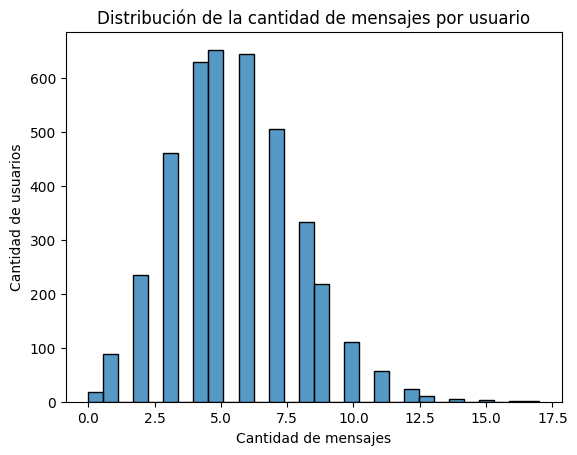

In [88]:
import seaborn as sns

# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', bins=30)
plt.title("Distribución de la cantidad de mensajes por usuario")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: 
- ....

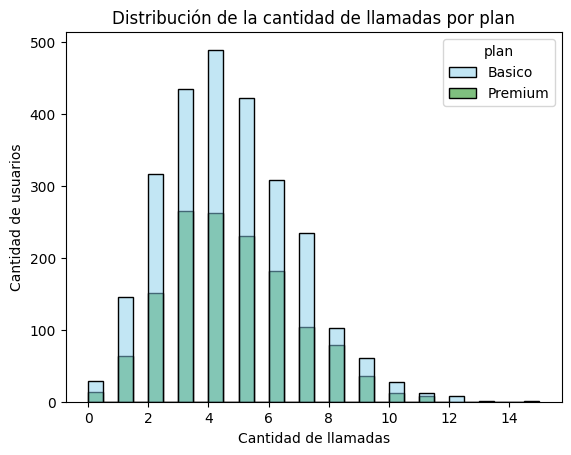

In [89]:


# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', bins=30, palette=['skyblue', 'green'])
plt.title("Distribución de la cantidad de llamadas por plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: 
- Distribución ...

['user_id', 'first_name', 'last_name', 'age', 'city', 'reg_date', 'plan', 'churn_date', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada', 'grupo_edad']


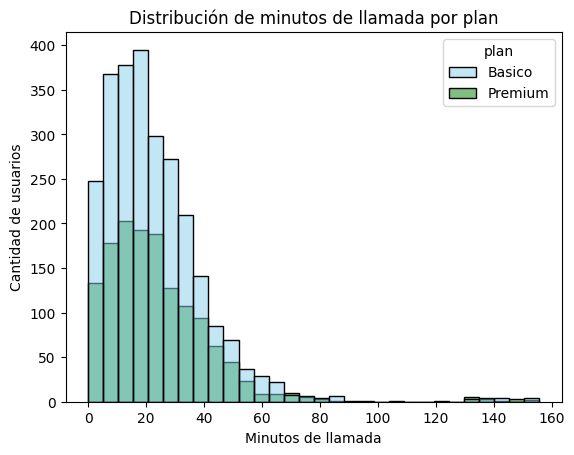

In [95]:

user_profile = user_profile.rename(columns={'min_llamadas': 'cant_minutos_llamada'})
print(user_profile.columns.tolist())


sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', bins=30, palette=['skyblue', 'green'])
plt.title("Distribución de minutos de llamada por plan")
plt.xlabel("Minutos de llamada")
plt.ylabel("Cantidad de usuarios")
plt.show()


### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

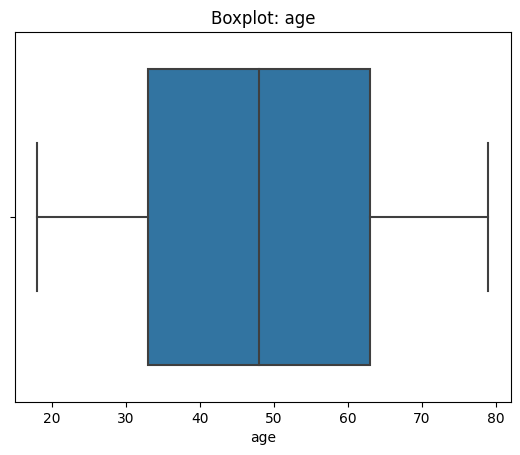

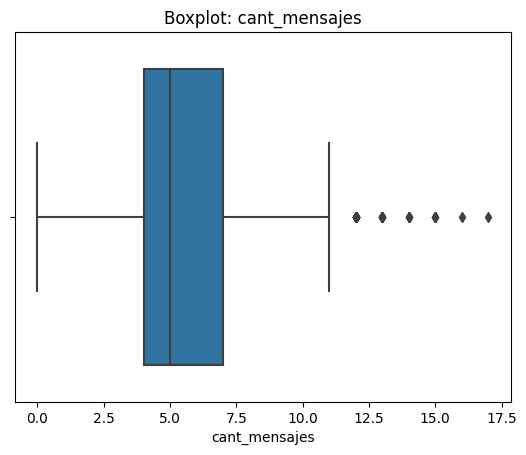

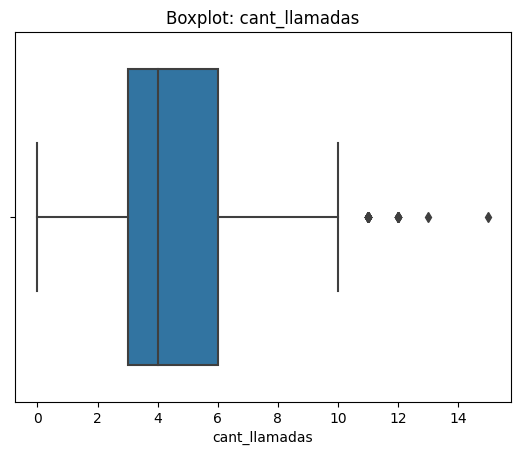

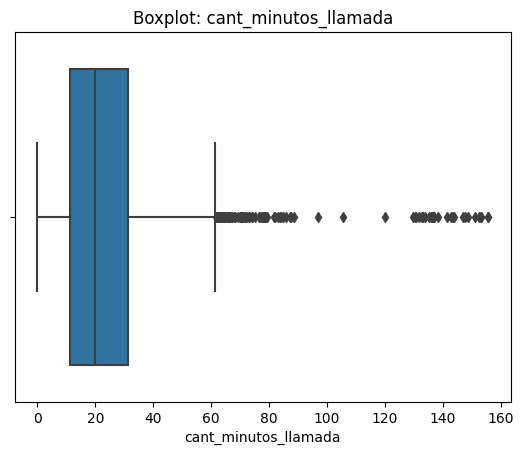

In [96]:

# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: ...(presenta o no outliers)
- cant_mensajes: ...
- cant_llamadas: ...
- cant_minutos_llamada: ...

In [97]:
# Calcular límites con el método IQR

columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
# Calcular límites con el método IQR
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    n_inferior = (user_profile[col] < limite_inferior).sum()
    n_superior = (user_profile[col] > limite_superior).sum()

    print(f"--- {col} ---")
    print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
    print(f"Límite inferior: {limite_inferior:.2f} -> outliers por debajo: {n_inferior}")
    print(f"Límite superior: {limite_superior:.2f} -> outliers por encima: {n_superior}")
    print()


--- age ---
Q1: 33.00 | Q3: 63.00 | IQR: 30.00
Límite inferior: -12.00 -> outliers por debajo: 0
Límite superior: 108.00 -> outliers por encima: 0

--- cant_mensajes ---
Q1: 4.00 | Q3: 7.00 | IQR: 3.00
Límite inferior: -0.50 -> outliers por debajo: 0
Límite superior: 11.50 -> outliers por encima: 45

--- cant_llamadas ---
Q1: 3.00 | Q3: 6.00 | IQR: 3.00
Límite inferior: -1.50 -> outliers por debajo: 0
Límite superior: 10.50 -> outliers por encima: 30

--- cant_minutos_llamada ---
Q1: 11.09 | Q3: 31.36 | IQR: 20.27
Límite inferior: -19.32 -> outliers por debajo: 0
Límite superior: 61.76 -> outliers por encima: 110



In [56]:

# Calcular límites con el método IQR
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'min_llamadas']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = user_profile[(user_profile[col] < limite_inferior) | (user_profile[col] > limite_superior)]

    print(f"--- {col} ---")
    print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
    print(f"Límite inferior: {limite_inferior:.2f} | Límite superior: {limite_superior:.2f}")
    print(f"Outliers: {len(outliers)} ({len(outliers) / len(user_profile) * 100:.2f}%)")
    print()

--- age ---
Q1: 33.00 | Q3: 63.00 | IQR: 30.00
Límite inferior: -12.00 | Límite superior: 108.00
Outliers: 0 (0.00%)

--- cant_mensajes ---
Q1: 4.00 | Q3: 7.00 | IQR: 3.00
Límite inferior: -0.50 | Límite superior: 11.50
Outliers: 45 (1.12%)

--- cant_llamadas ---
Q1: 3.00 | Q3: 6.00 | IQR: 3.00
Límite inferior: -1.50 | Límite superior: 10.50
Outliers: 30 (0.75%)

--- min_llamadas ---
Q1: 11.09 | Q3: 31.36 | IQR: 20.27
Límite inferior: -19.32 | Límite superior: 61.76
Outliers: 110 (2.75%)



💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- cant_llamadas: mantener o no outliers, porqué?
- cant_minutos_llamada: mantener o no outliers, porqué?

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [101]:
# Crear columna grupo_uso

# Primero, asegúrate de que no haya nulos en el consumo
cols_uso = ['cant_mensajes', 'cant_llamadas']
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

def clasificar_uso(fila):
    if fila['cant_llamadas'] < 5 and fila['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif fila['cant_llamadas'] < 10 and fila['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

# Verificar
print(user_profile['grupo_uso'].value_counts(dropna=False))



Uso medio    2941
Bajo uso      781
Alto uso      278
Name: grupo_uso, dtype: int64


In [104]:


# verificar cambios
user_profile.head()

user_profile.info()

# confirmar que no hay nulos en las columnas de consumo y grupo_uso
print(user_profile[['cant_mensajes', 'cant_llamadas', 'grupo_uso']].isna().sum())

# número de filas (debe ser igual a len(users))
print(len(users), len(user_profile))


<class 'pandas.core.frame.DataFrame'>
Int64Index: 4000 entries, 0 to 3999
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   user_id               4000 non-null   int64         
 1   first_name            4000 non-null   object        
 2   last_name             4000 non-null   object        
 3   age                   4000 non-null   float64       
 4   city                  3904 non-null   object        
 5   reg_date              3960 non-null   datetime64[ns]
 6   plan                  4000 non-null   object        
 7   churn_date            466 non-null    object        
 8   cant_mensajes         4000 non-null   float64       
 9   cant_llamadas         4000 non-null   float64       
 10  cant_minutos_llamada  3999 non-null   float64       
 11  grupo_edad            4000 non-null   category      
 12  grupo_uso             4000 non-null   object        
dtypes: category(1), da

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [57]:

# Crear columna grupo_edad
bins = [0, 25, 35, 45, 55, 65, 120]
labels = ['18-25', '26-35', '36-45', '46-55', '56-65', '66+']

user_profile['grupo_edad'] = pd.cut(user_profile['age'], bins=bins, labels=labels, right=True)

# Verificar
print(user_profile['grupo_edad'].value_counts(dropna=False).sort_index())



18-25    489
26-35    689
36-45    650
46-55    687
56-65    625
66+      860
Name: grupo_edad, dtype: int64


In [58]:


# solo las columnas relevantes, para ver el resultado a simple vista
print(user_profile[['age', 'grupo_edad']].head(10))

# nulos en grupo_edad (debe dar 0 si todas las edades son válidas)
print(user_profile['grupo_edad'].isna().sum())

# número de filas (no debe haber cambiado)
print(len(users), len(user_profile))


    age grupo_edad
0  38.0      36-45
1  53.0      46-55
2  57.0      56-65
3  69.0        66+
4  63.0      56-65
5  61.0      56-65
6  39.0      36-45
7  70.0        66+
8  76.0        66+
9  47.0      46-55
0
4000 4000


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

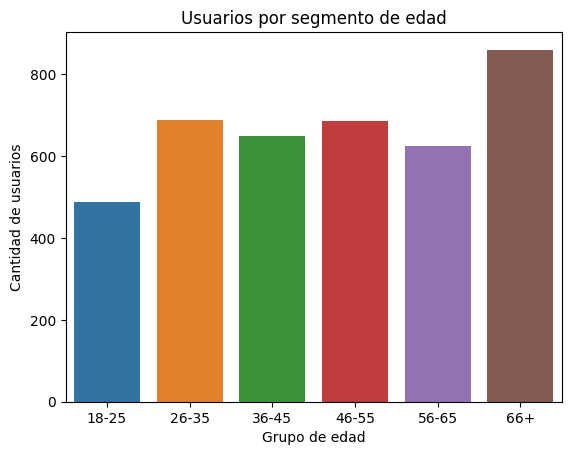

<AxesSubplot:xlabel='grupo_edad', ylabel='count'>

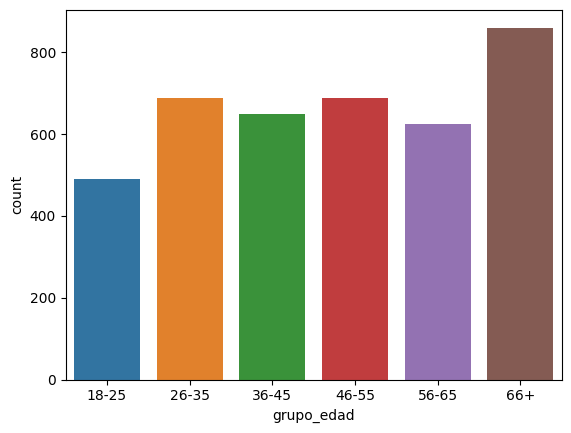

In [105]:
# Visualización de los segmentos por uso
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')
plt.title("Usuarios por segmento de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()

orden_edad = ['18-25', '26-35', '36-45', '46-55', '56-65', '66+']
sns.countplot(data=user_profile, x='grupo_edad', order=orden_edad)

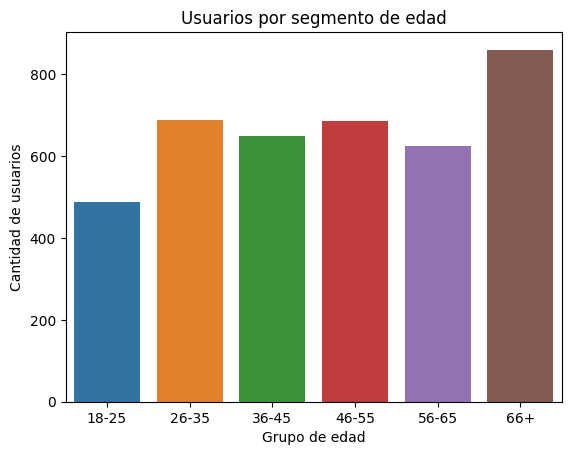

In [107]:

sns.countplot(data=user_profile, x='grupo_edad')
plt.title("Usuarios por segmento de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()
bins = [0, 25, 35, 45, 55, 65, 120]
labels = ['18-25', '26-35', '36-45', '46-55', '56-65', '66+']
user_profile['grupo_edad'] = pd.cut(user_profile['age'], bins=bins, labels=labels, right=True)


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

#
## Análisis ejecutivo


⚠️ **Problemas detectados en los datos**

Tabla de usuarios (users): El campo ciudad presenta un 11.7% de valores nulos (469 registros) además del carácter inválido ? como nulo disfrazado, lo que impide la segmentación geográfica. Asimismo, se detectaron valores centinela en edad (-999) y fechas de registro futuras (posteriores al corte de 2024). Por otro lado, el 88.35% de nulos en la fecha de baja (churn_date, 3,534 registros) no constituye un error, sino que identifica a los usuarios activos y sirve como base para medir la fidelización del cliente. 

Tabla de uso (usage): Los nulos en duración (55.19%) y longitud (44.74%) son estructurales  corresponden exclusivamente a llamadas y mensajes, respectivamente, por lo que se conservaron sin imputar. En fecha (date) se eliminaron únicamente 50 registros nulos (0.125%) por tener un impacto marginal.


Recomendación de captura: Estandarizar los valores faltantes mediante NULL real (eliminando símbolos como ? o -999), implementar reglas de validación de fechas y rangos de edad en el formulario de registro, y establecer la ciudad como campo obligatorio debido a su criticidad para la estrategia comercial.

🔍 **Segmentos por Edad**
1. Cartera adulta y equilibrada: Los segmentos intermedios mantienen una participación uniforme de entre el 16% y el 17% por década: 26–35 años (689), 46–55 años (687), 36–45 años (650) y 56–65 años (625).

Predominio senior (66+ años): Representa el 21.5% del total (860 usuarios). Aunque su tamaño responde en parte a que es un intervalo abierto, confirma una base sólida de adultos mayores con alta estabilidad.

Baja penetración joven (18–25 años): Es el grupo menor con un 12.2% (489 usuarios). Más allá de ser un rango más estrecho (8 años), evidencia una oportunidad clara de captación mediante ofertas orientadas al consumo digital y mensajería.

2. Matiz sobre el 66+.
Es un rango abierto (66 hasta 120), mientras los demás abarcan 10 años, por lo que se ve más grande. Aun así, confirma que hay una base importante de adultos mayores.

3. Los jóvenes están subrepresentados.
Solo 12.2% de los usuarios tiene entre 18 y 25 años. Es el segmento con menor interaccion o presencia, lo que abre la oprtunidad de estudiar como se estan comunicando los jovenes de 18 años e implememntar estrategias que se acomoden y potenciar ese rango de edad o prensencia en la compañía.

📊 **Segmentos por Nivel de Uso**

Comportamiento típico moderado: Ambas métricas muestran una distribución con asimetría positiva (sesgo a la derecha) y exactamente la misma dispersión central ($IQR = 3$). El 50% central de los usuarios envía entre 4 y 7 mensajes (mediana: 5) y realiza entre 3 y 6 llamadas (mediana: 4).Usuarios intensivos (outliers superiores): Se identificaron valores atípicos únicamente en el extremo superior (12 a 17 mensajes y 11 a 15 llamadas). Dado que representan consumo real y no errores técnicos, se conservaron en el análisis; este grupo eleva el promedio general, confirmando que la mediana es la métrica más fiel para describir al usuario promedio


La empresa tiene una base de 4,000 clientes, mayormente adultos, con pocos jóvenes. Los clientes usan los servicios de forma moderada, y una minoría lo hace de forma intensa. Esa minoría es la mejor oportunidad de venta del plan Premium. Los clientes de poco uso necesitan incentivos para no irse. Además, los datos tienen fallas de captura (ciudades faltantes, edades y fechas inválidas) que limitan el análisis geográfico y de fidelización, y que conviene corregir desde el origen

💡 **Recomendaciones**
1. Arreglar cómo se guarda la información de los clientes

1.Gobernanza y validación en el registro de clientes

Acción: Establecer la ciudad como campo obligatorio, bloquear fechas futuras o edades fuera de rango en el sistema y estandarizar los valores vacíos como NULL real en lugar de ? o -999.

Impacto: Habilitará la segmentación geográfica confiable para dirigir campañas comerciales por ciudad.

2.Migración proactiva (Upselling) al Plan Premium

Acción: Dirigir campañas personalizadas con un mes promocional a los usuarios ubicados en el extremo superior de consumo (más de 11 llamadas o 12 mensajes).

Impacto: Incrementa el ingreso promedio por usuario (ARPU) y evita la fricción por cobros de excedentes en el plan Básico.

3.Retención preventiva en usuarios de bajo uso

Acción: Activar incentivos automáticos (bonos de minutos, paquetes de mensajes o descuentos temporales) para clientes por debajo del primer cuartil de uso.

Impacto: Reduce la tasa de abandono (churn) a un costo significativamente menor que la adquisición de clientes nuevos.

4.Fidelización y experiencia simplificada para adultos mayores (66+)

Acción: Diseñar planes enfocados en voz, con facturación clara, navegación intuitiva en la aplicación y canales de atención asistida (telefónica o presencial).

Impacto: Protege el segmento más grande y leal de la compañía.

5.Captación del segmento joven (18–25 años)

Acción: Lanzar planes de entrada económicos con alta capacidad de mensajería y datos, pautados en redes sociales y entornos universitarios.

Impacto: Rejuvenece la base de clientes y asegura valor de vida del cliente (LTV) a largo plazo.

Conclusiones:Ambas variables ( llamdas y menddsjes ) presentan distribuciones muy similares con asimetría positiva (sesgo a la derecha), concentrando el 50% central de los registros en rangos bajos y moderados: entre 4 y 7 mensajes (mediana de 5) y entre 3 y 6 llamadas (mediana de 4). El volumen de mensajes es consistentemente superior en 1 unidad respecto al de llamadas en todos sus cuartiles, aunque mantienen exactamente la misma dispersión central ($IQR = 3$). Asimismo, en ambos casos existen valores atípicos (outliers) únicamente en el extremo superior (a partir de 12 en mensajes y de 11 en llamadas), lo que indica que, si bien la mayoría tiene una actividad moderada, existe un segmento reducido de usuarios con interacción intensiva que desplaza la media hacia arriba, haciendo de la mediana la métrica más adecuada para representar el comportamiento típico. 


La base de 4,000 usuarios presenta una distribución etaria equilibrada y sin valores faltantes. Los segmentos intermedios (entre 26 y 65 años) mantienen una participación muy uniforme, aportando cada década alrededor del 16% al 17% del total. Por su parte, el grupo de 18 a 25 años representa la menor proporción (12.2%) debido a que abarca un rango de edad más estrecho, mientras que el segmento de 66 años o más concentra el mayor volumen (21.5%) al agrupar toda la población senior. En conjunto, se trata de una cartera de usuarios madura y bien distribuida a lo largo de todas las etapas adultas. lo que sugiere que el servicio de la empresa de telefonia debe potenciar su servicio facil de entender y practivo y que comprenda su campañas en las personas maduras y consolidacion en cuanto a la versatilidad tanto el manejo de los pagos, faciliad en el uso de la aplicacion e interaction con el cliente. 

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`